<a href="https://colab.research.google.com/github/mishrasatyam9720-debug/model_from_scrartch/blob/main/handson_nn_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)

X shape: (500, 2)
y shape: (500, 1)


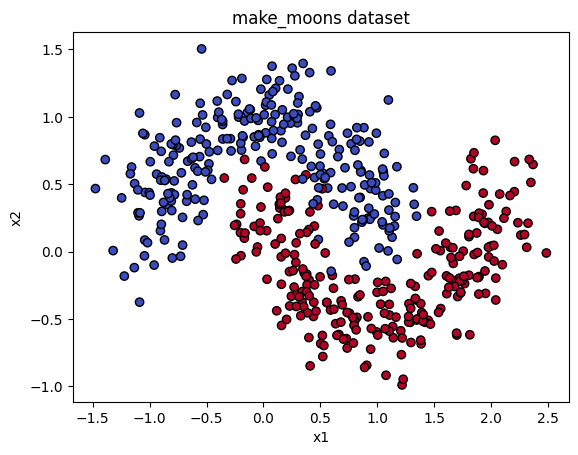

In [49]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
y = y.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Visualize
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap='coolwarm', edgecolor='k')
plt.title("make_moons dataset")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

In [50]:
print(X[:5])
print("="*50)
print(y[:5])

[[ 0.83085779 -0.33434228]
 [ 0.99170955  0.87899966]
 [ 1.1072453  -0.47034376]
 [-0.14089918  1.03314844]
 [ 0.40559217  1.32852876]]
[[1]
 [0]
 [1]
 [0]
 [0]]


In [51]:
# First split: separate test set (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Second split: train (70%) and validation (10%) from the remaining 80%
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=42  # 0.125 * 0.8 = 0.1
)

print(f"Train: {X_train.shape[0]} samples")
print(f"Val:   {X_val.shape[0]} samples")
print(f"Test:  {X_test.shape[0]} samples")

Train: 350 samples
Val:   50 samples
Test:  100 samples


In [43]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # 'a' is already sigmoid(z)
    return a * (1 - a)

In [52]:
input_size = 2
hidden1_size = 4
hidden2_size = 4
output_size = 1

W1 = np.random.randn(input_size, hidden1_size) * 0.5
b1 = np.zeros((1, hidden1_size))

W2 = np.random.randn(hidden1_size, hidden2_size) * 0.5
b2 = np.zeros((1, hidden2_size))

W3 = np.random.randn(hidden2_size, output_size) * 0.5
b3 = np.zeros((1, output_size))

print("W1:", W1.shape, "| W2:", W2.shape, "| W3:", W3.shape)

W1: (2, 4) | W2: (4, 4) | W3: (4, 1)


In [53]:
learning_rate = 1.0
epochs = 2000
train_losses = []
val_losses = []
epsilon = 1e-15  # for numerical stability in log

for epoch in range(epochs):
    # ---- Forward pass on TRAIN ----
    z1 = X_train @ W1 + b1
    a1 = sigmoid(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    z3 = a2 @ W3 + b3
    a3 = sigmoid(z3)        # final prediction

    # ---- Train Loss (Binary Cross-Entropy) ----
    train_loss = -np.mean(y_train * np.log(a3 + epsilon) +
                          (1 - y_train) * np.log(1 - a3 + epsilon))
    train_losses.append(train_loss)

    # ---- Backward pass ----
    # Output layer: with sigmoid + BCE, the gradient simplifies beautifully to (a3 - y)
    # (the sigmoid derivative cancels out — this is why we pair them!)
    dz3 = (a3 - y_train) / len(y_train)
    dW3 = a2.T @ dz3
    db3 = np.sum(dz3, axis=0, keepdims=True)

    # Hidden layer 2
    dz2 = (dz3 @ W3.T) * sigmoid_derivative(a2)
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Hidden layer 1
    dz1 = (dz2 @ W2.T) * sigmoid_derivative(a1)
    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    # ---- Update weights ----
    W3 -= learning_rate * dW3;  b3 -= learning_rate * db3
    W2 -= learning_rate * dW2;  b2 -= learning_rate * db2
    W1 -= learning_rate * dW1;  b1 -= learning_rate * db1

    # ---- Validation Loss (forward pass only, no update) ----
    a1_v = sigmoid(X_val @ W1 + b1)
    a2_v = sigmoid(a1_v @ W2 + b2)
    a3_v = sigmoid(a2_v @ W3 + b3)
    val_loss = -np.mean(y_val * np.log(a3_v + epsilon) +
                        (1 - y_val) * np.log(1 - a3_v + epsilon))
    val_losses.append(val_loss)

    if epoch % 200 == 0:
        print(f"Epoch {epoch:5d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch     0 | Train Loss: 0.6988 | Val Loss: 0.6965
Epoch   200 | Train Loss: 0.3497 | Val Loss: 0.2265
Epoch   400 | Train Loss: 0.3124 | Val Loss: 0.1701
Epoch   600 | Train Loss: 0.2990 | Val Loss: 0.1699
Epoch   800 | Train Loss: 0.2084 | Val Loss: 0.1280
Epoch  1000 | Train Loss: 0.1181 | Val Loss: 0.0597
Epoch  1200 | Train Loss: 0.0882 | Val Loss: 0.0365
Epoch  1400 | Train Loss: 0.0748 | Val Loss: 0.0291
Epoch  1600 | Train Loss: 0.0682 | Val Loss: 0.0280
Epoch  1800 | Train Loss: 0.0642 | Val Loss: 0.0286


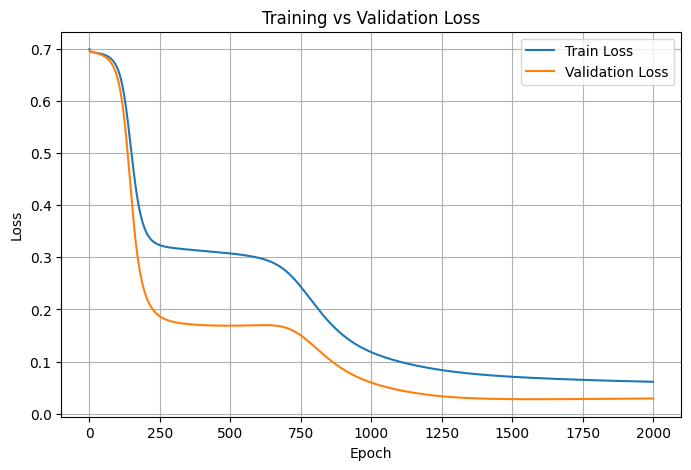

In [54]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend(); plt.grid(True)
plt.show()

In [58]:
def predict(X_input):
    a1 = sigmoid(X_input @ W1 + b1)
    a2 = sigmoid(a1 @ W2 + b2)
    a3 = sigmoid(a2 @ W3 + b3)
    return a3


# Accuracy on Train, Validation and Test
for name, X_, y_ in [
    ("Train", X_train, y_train),
    ("Val", X_val, y_val),
    ("Test", X_test, y_test)
]:
    preds = predict(X_)

    # Convert probabilities into classes (0 or 1)
    predicted_classes = (preds > 0.5).astype(int)

    # Count correct predictions
    correct = (predicted_classes == y_)
    correct_count = np.sum(correct)

    # Count total predictions
    total_count = len(y_)

    # Calculate accuracy
    accuracy = (correct_count / total_count) * 100

    print(f"{name:5s} Accuracy: {accuracy:.2f}%")

Train Accuracy: 97.71%
Val   Accuracy: 98.00%
Test  Accuracy: 99.00%
